# Backtest and Evaluation

**Purpose.** Turn the model into a strategy, put it against buy-and-hold with
real costs, and evaluate it with a distribution of outcomes rather than one
equity curve.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.color": "#D9E2E4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.width", 170)

TEAL, AMBER, RED, GREY = "#0E7C86", "#C77700", "#C0392B", "#7A8B90"

RAW = Path("../data/01-raw")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

TRADING_DAYS = 252
D_STAR = 0.65

# Commission plus slippage, per side. Five basis points is realistic for a
# liquid US equity at retail size. It is deliberately not optimistic.
COST_BPS = 5.0

bars = {path.stem: pd.read_parquet(path) for path in sorted(RAW.glob("*.parquet"))}

print(f"Loaded {len(bars)} tickers")
print(f"Cost assumption: {COST_BPS} bps per side, "
      f"{2 * COST_BPS} bps per round trip")

Loaded 11 tickers
Cost assumption: 5.0 bps per side, 10.0 bps per round trip


### What costs actually do to a daily strategy

Before building anything, I want the cost arithmetic in front of me, because it
is the single thing most likely to kill this.

A buy-and-hold position trades **once**. A daily long/short that flips sign
frequently trades close to every day, and each flip is a full round trip.

I compute the drag directly rather than reasoning about it, using a random
signal so there is no skill involved — only turnover.

In [2]:
def backtest(positions, returns, cost_bps=COST_BPS):
    """Position set at t using information at t, earning the return t to t+1."""
    position = positions.reindex(returns.index).fillna(0.0)

    gross = position * returns

    # Turnover is how much the position changed. The first day is a full entry.
    turnover = position.diff().abs().fillna(position.abs())
    cost = turnover * cost_bps / 10_000

    return pd.DataFrame({
        "position": position,
        "gross": gross,
        "cost": cost,
        "net": gross - cost,
        "turnover": turnover,
    })


spy_returns = bars["SPY"]["adj_close"].pct_change().dropna()

hold = backtest(pd.Series(1.0, index=spy_returns.index), spy_returns)

rng = np.random.default_rng(0)
coin_flip = pd.Series(np.sign(rng.normal(size=len(spy_returns))), index=spy_returns.index)
flipping = backtest(coin_flip, spy_returns)

print(f"{'':22s}{'turnover':>12s}{'total cost':>14s}")
print(f"{'buy and hold':22s}{hold['turnover'].sum():>12.1f}{hold['cost'].sum():>13.2%}")
print(f"{'daily long/short':22s}{flipping['turnover'].sum():>12.1f}{flipping['cost'].sum():>13.2%}")
print()
print(f"Cost ratio: {flipping['cost'].sum() / max(hold['cost'].sum(), 1e-9):,.0f}x")

                          turnover    total cost
buy and hold                   1.0        0.05%
daily long/short            5063.0      253.15%

Cost ratio: 5,063x


### Features, model and out-of-sample predictions

Same features and the same purged validation as notebook 03. What is new is
that I keep the **predictions** this time, stitched together across folds into
one continuous out-of-sample series.

Every prediction in that series was made by a model that had not seen the day it
is predicting, nor the embargo window before it. That is what makes the backtest
meaningful rather than a description of the past.

In [3]:
def rsi(close, window=14):
    """Wilder's RSI, backward-looking only."""
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / window, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / window, adjust=False).mean()

    return (100 - 100 / (1 + gain / loss.replace(0, np.nan))).fillna(50)


def fracdiff(series, d, threshold=1e-4):
    """Fixed-width fractional differencing, from notebook 02."""
    weights = [1.0]

    for k in range(1, 10_000):
        weight = -weights[-1] * (d - k + 1) / k
        if abs(weight) < threshold:
            break
        weights.append(weight)

    weights = np.array(weights)
    values = pd.Series(series).dropna()

    if len(values) <= len(weights):
        return pd.Series(dtype=float)

    transformed = np.convolve(values.to_numpy(dtype=float), weights, mode="valid")

    return pd.Series(transformed, index=values.index[len(weights) - 1 :])


def build_features(frame, d_star=D_STAR):
    """The feature set carried forward from notebook 03."""
    close = frame["adj_close"]
    daily = close.pct_change()
    features = pd.DataFrame(index=frame.index)

    for window in [1, 2, 3, 5, 10, 21]:
        features[f"ret_{window}d"] = close.pct_change(window)

    for window in [5, 10, 21, 63]:
        features[f"px_over_ma_{window}"] = close / close.rolling(window).mean() - 1

    for window in [10, 21, 63]:
        features[f"vol_{window}d"] = daily.rolling(window).std()

    features["rsi_14"] = rsi(close, 14)
    features["vol_ratio"] = features["vol_10d"] / features["vol_63d"]
    features["volume_ratio"] = frame["volume"] / frame["volume"].rolling(21).mean()
    features["fracdiff"] = fracdiff(np.log(close), d_star)

    return features

In [4]:
def purged_splits(n_rows, n_splits=5, embargo_pct=0.01, label_span=1):
    """Walk-forward splits with an embargo gap, from notebook 03."""
    fold_size = n_rows // (n_splits + 1)
    embargo = int(n_rows * embargo_pct)

    for i in range(n_splits):
        train_end = fold_size * (i + 1)
        test_start = train_end + embargo
        test_end = min(test_start + fold_size, n_rows)

        if test_start >= n_rows:
            break

        train_index = np.arange(0, max(train_end - label_span, 0))
        test_index = np.arange(test_start, test_end)

        if len(test_index) == 0:
            break

        yield train_index, test_index


spy = bars["SPY"]
X = build_features(spy)
y = spy["adj_close"].pct_change().shift(-1)

data = X.join(y.rename("target")).dropna()
features, target = data[X.columns], data["target"]

predictions = pd.Series(index=data.index, dtype=float)

for train_index, test_index in purged_splits(len(data)):
    model = RandomForestRegressor(
        n_estimators=200, max_depth=5, min_samples_leaf=50,
        max_features="sqrt", random_state=42, n_jobs=-1,
    )
    model.fit(features.iloc[train_index], target.iloc[train_index])
    predictions.iloc[test_index] = model.predict(features.iloc[test_index])

predictions = predictions.dropna()
realised = target.loc[predictions.index]

print(f"Out-of-sample predictions : {len(predictions):,}")
print(f"Period                    : {predictions.index[0].date()} to {predictions.index[-1].date()}")
print(f"Information coefficient   : {stats.spearmanr(predictions, realised).statistic:+.4f}")
print(f"Directional hit rate      : {(np.sign(predictions) == np.sign(realised)).mean():.4f}")
print(f"Share of up days          : {(realised > 0).mean():.4f}")

Out-of-sample predictions : 4,047
Period                    : 2008-11-28 to 2024-12-27
Information coefficient   : +0.0245
Directional hit rate      : 0.5172
Share of up days          : 0.5532


### Turning a prediction into a position

Three rules, all using the same predictions:

**Binary long/short.** Full long when the prediction is positive, full short
when negative. Leans entirely on the sign, so it should inherit the hit-rate
problem.

**Scaled by conviction.** Position proportional to how far the prediction sits
from its recent average, capped at full size. Uses the ranking skill rather than
the sign, and trades less because small predictions produce small positions.

**Long only when positive.** Long when the prediction is positive, flat
otherwise. No shorting, and no position at all on the days the model dislikes.

All three are shifted by one day. The prediction made using data through today
sets the position I hold tomorrow. **Without that shift I would be trading on
information I did not have.**

In [5]:
def binary_position(predicted):
    """Full long or full short on the sign of the prediction."""
    return pd.Series(np.sign(predicted), index=predicted.index)


def scaled_position(predicted, window=63, cap=1.0):
    """Position proportional to conviction, standardised on a rolling window.

    The rolling statistics are backward-looking, so no future information
    enters the scaling.
    """
    centred = predicted - predicted.rolling(window).mean()
    spread = predicted.rolling(window).std()
    z_score = (centred / spread.replace(0, np.nan)).fillna(0.0)

    return z_score.clip(-cap, cap)


def long_only_position(predicted):
    """Long when the prediction is positive, flat otherwise."""
    return pd.Series((predicted > 0).astype(float), index=predicted.index)


# The shift is what keeps this honest: today's prediction sets tomorrow's trade.
strategies = {
    "binary long/short": binary_position(predictions).shift(1),
    "scaled by conviction": scaled_position(predictions).shift(1),
    "long only": long_only_position(predictions).shift(1),
    "buy and hold": pd.Series(1.0, index=predictions.index),
}

period_returns = realised.shift(1).dropna()

books = {
    name: backtest(position, period_returns)
    for name, position in strategies.items()
}

pd.DataFrame({
    name: {
        "mean position": book["position"].mean(),
        "time invested": (book["position"].abs() > 0.01).mean(),
        "total turnover": book["turnover"].sum(),
        "total cost": book["cost"].sum(),
    }
    for name, book in books.items()
}).T.round(4)

,mean position,time invested,total turnover,total cost
binary long/short,0.3070,1.0000,1807.0000,0.9035
scaled by conviction,-0.0143,0.9740,1773.3314,0.8867
long only,0.6535,0.6535,903.0000,0.4515
buy and hold,1.0000,1.0000,1.0000,0.0005


### Performance, gross and net

I report both. Gross tells me whether the model found anything; net tells me
whether I could have kept it. The gap between them is what the market charges
for acting on a signal.

In [6]:
def performance(returns, days=TRADING_DAYS):
    """Standard performance statistics for a daily return series."""
    series = pd.Series(returns).dropna()

    if len(series) < 2 or series.std() == 0:
        return {}

    equity = (1 + series).cumprod()
    total = equity.iloc[-1] - 1
    years = len(series) / days

    downside = series[series < 0].std()
    drawdown = (equity / equity.cummax() - 1).min()

    return {
        "total_return": total,
        "cagr": (1 + total) ** (1 / years) - 1 if total > -1 else np.nan,
        "ann_vol": series.std() * np.sqrt(days),
        "sharpe": series.mean() / series.std() * np.sqrt(days),
        "sortino": series.mean() / downside * np.sqrt(days) if downside > 0 else np.nan,
        "max_drawdown": drawdown,
        "hit_rate": (series > 0).mean(),
    }


summary = pd.DataFrame({
    name: {
        **{f"{k}_gross": v for k, v in performance(book["gross"]).items()},
        **{f"{k}_net": v for k, v in performance(book["net"]).items()},
    }
    for name, book in books.items()
}).T

summary[["sharpe_gross", "sharpe_net", "cagr_gross", "cagr_net",
         "ann_vol_net", "max_drawdown_net"]].round(4)

,sharpe_gross,sharpe_net,cagr_gross,cagr_net,ann_vol_net,max_drawdown_net
binary long/short,0.5901,0.2787,0.0945,0.0347,0.1808,-0.5141
scaled by conviction,0.3276,-0.0977,0.0347,-0.0209,0.1299,-0.5236
long only,0.8970,0.7027,0.1268,0.0955,0.1448,-0.2240
buy and hold,0.8476,0.8473,0.1465,0.1464,0.1806,-0.3372


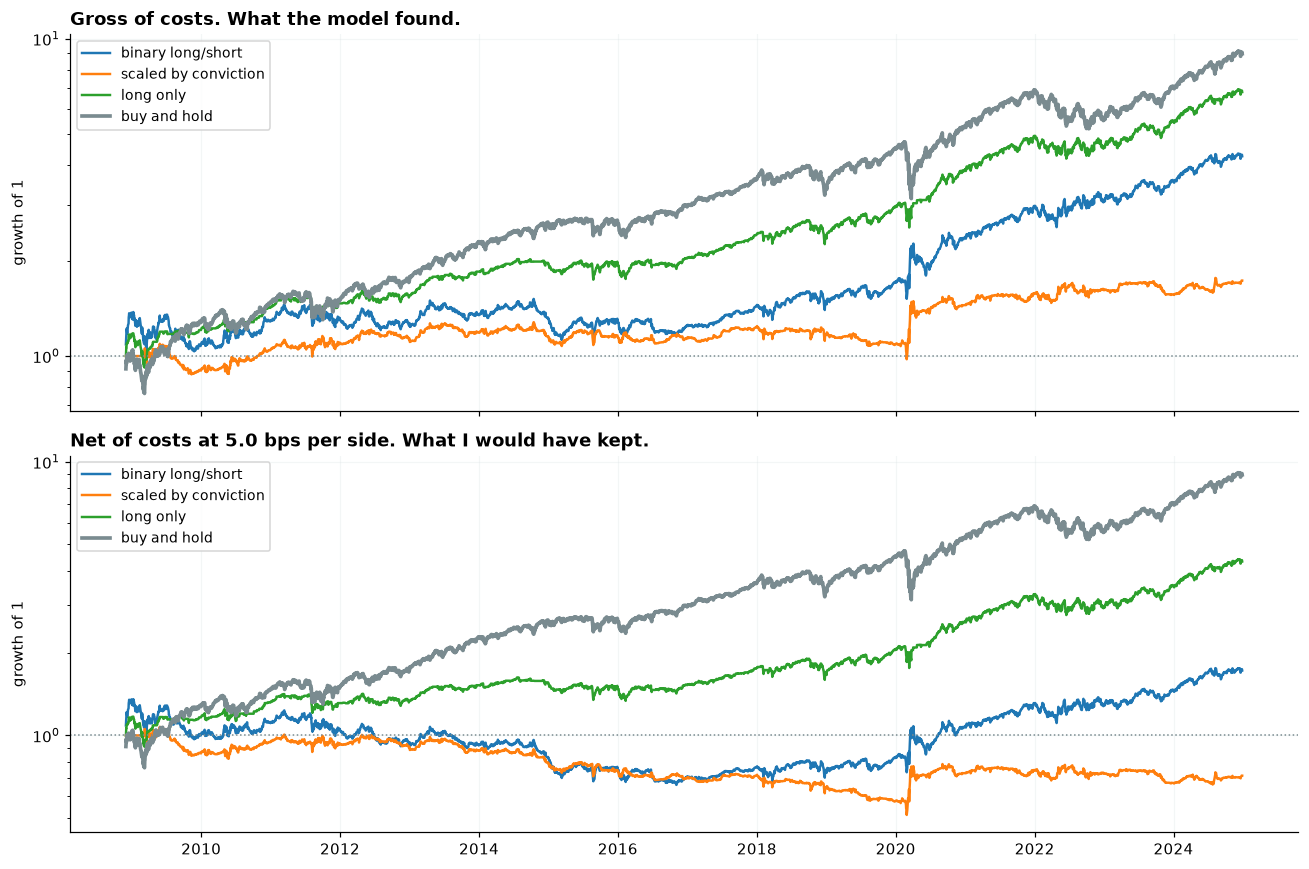

In [7]:
figure, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for name, book in books.items():
    colour = GREY if name == "buy and hold" else None
    width = 2.4 if name == "buy and hold" else 1.6

    axes[0].plot((1 + book["gross"]).cumprod(), label=name, lw=width, color=colour)
    axes[1].plot((1 + book["net"]).cumprod(), label=name, lw=width, color=colour)

axes[0].set_title("Gross of costs. What the model found.", loc="left", fontweight="bold")
axes[1].set_title(f"Net of costs at {COST_BPS} bps per side. What I would have kept.",
                  loc="left", fontweight="bold")

for axis in axes:
    axis.set_yscale("log")
    axis.set_ylabel("growth of 1")
    axis.axhline(1, color=GREY, lw=1, ls=":")
    axis.legend(fontsize=9)

save("04_equity_curves")
plt.show()

### One equity curve is one sample

This is the paper's Pitfall #9. A backtest shows what would have happened along
**one** historical path. The market could have delivered the same statistical
behaviour in a different order and produced a very different curve.

So I resample. Draw new return paths from the strategy's own returns, run each
one, and look at the distribution of outcomes rather than the single number.

**Why blocks and not individual days.** Notebook 01 found strong volatility
clustering: quiet periods follow quiet periods. Resampling day by day destroys
that, producing paths far smoother than reality and Sharpe ratios that are too
flattering. Resampling in blocks of roughly a month keeps the clustering intact.

I check that it does rather than assuming it.

In [8]:
def block_bootstrap(returns, n_runs=1000, block=21, seed=42):
    """Resample in blocks so volatility clustering survives."""
    values = np.asarray(pd.Series(returns).dropna())
    n = len(values)

    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block, size=(n_runs, n_blocks))

    paths = np.empty((n_runs, n_blocks * block))

    for i in range(n_runs):
        paths[i] = np.concatenate([values[s : s + block] for s in starts[i]])

    return paths[:, :n]


reference = books["buy and hold"]["net"].dropna()

blocked = block_bootstrap(reference, n_runs=200, block=21)
daily = block_bootstrap(reference, n_runs=200, block=1)

print("Volatility clustering, measured as autocorrelation of absolute returns")
print(f"  original series        : {reference.abs().autocorr(1):.4f}")
print(f"  block bootstrap (21d)  : {np.mean([pd.Series(p).abs().autocorr(1) for p in blocked]):.4f}")
print(f"  daily bootstrap  (1d)  : {np.mean([pd.Series(p).abs().autocorr(1) for p in daily]):.4f}")
print()
print("The daily version destroys the clustering, which is why blocks are used.")

Volatility clustering, measured as autocorrelation of absolute returns
  original series        : 0.2988
  block bootstrap (21d)  : 0.2732
  daily bootstrap  (1d)  : 0.0013

The daily version destroys the clustering, which is why blocks are used.


In [9]:
N_RUNS = 1000

distributions = {}

for name, book in books.items():
    net = book["net"].dropna()
    paths = block_bootstrap(net, n_runs=N_RUNS, block=21)

    distributions[name] = pd.DataFrame({
        "sharpe": paths.mean(axis=1) / paths.std(axis=1) * np.sqrt(TRADING_DAYS),
        "total_return": (1 + paths).prod(axis=1) - 1,
        "max_drawdown": [
            float((pd.Series(1 + p).cumprod() / pd.Series(1 + p).cumprod().cummax() - 1).min())
            for p in paths
        ],
    })

sharpe_table = pd.DataFrame({
    name: {
        "actual": performance(books[name]["net"])["sharpe"],
        "median": frame["sharpe"].median(),
        "p05": frame["sharpe"].quantile(0.05),
        "p95": frame["sharpe"].quantile(0.95),
        "share_positive": (frame["sharpe"] > 0).mean(),
        "share_beating_hold": (
            frame["sharpe"] > performance(books["buy and hold"]["net"])["sharpe"]
        ).mean(),
    }
    for name, frame in distributions.items()
}).T

sharpe_table.round(4)

,actual,median,p05,p95,share_positive,share_beating_hold
binary long/short,0.2787,0.2113,-0.1403,0.5478,0.849,0.000
scaled by conviction,-0.0977,-0.1036,-0.5085,0.2544,0.315,0.000
long only,0.7027,0.6736,0.3482,1.0127,1.000,0.221
buy and hold,0.8473,0.8696,0.4964,1.2772,1.000,0.533


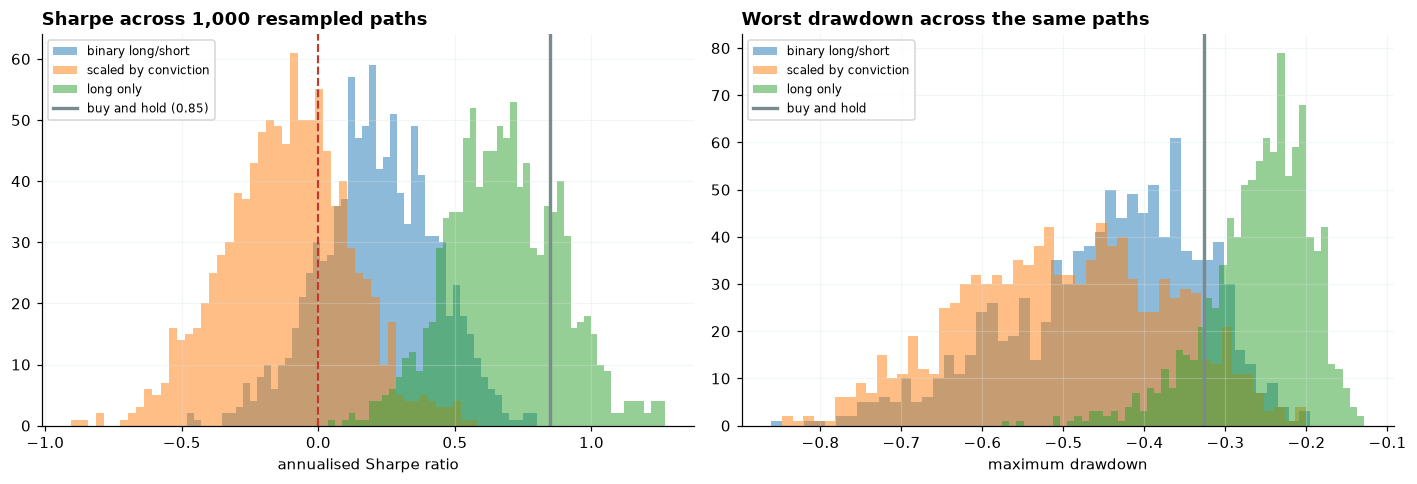

In [10]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, frame in distributions.items():
    if name == "buy and hold":
        continue
    axes[0].hist(frame["sharpe"], bins=50, alpha=0.5, label=name)

hold_sharpe = performance(books["buy and hold"]["net"])["sharpe"]
axes[0].axvline(hold_sharpe, color=GREY, lw=2.2, label=f"buy and hold ({hold_sharpe:.2f})")
axes[0].axvline(0, color=RED, ls="--", lw=1.4)
axes[0].set_title(f"Sharpe across {N_RUNS:,} resampled paths", loc="left", fontweight="bold")
axes[0].set_xlabel("annualised Sharpe ratio")
axes[0].legend(fontsize=8)

for name, frame in distributions.items():
    if name == "buy and hold":
        continue
    axes[1].hist(frame["max_drawdown"], bins=50, alpha=0.5, label=name)

axes[1].axvline(distributions["buy and hold"]["max_drawdown"].median(),
                color=GREY, lw=2.2, label="buy and hold")
axes[1].set_title("Worst drawdown across the same paths", loc="left", fontweight="bold")
axes[1].set_xlabel("maximum drawdown")
axes[1].legend(fontsize=8)

save("04_monte_carlo")
plt.show()

### Correcting the Sharpe ratio for how it was found

Two corrections, both from the paper, both pushing the same way: the Sharpe
ratio I measured is too flattering.

**The probabilistic Sharpe ratio** corrects for the sample. The usual formula
assumes normal returns, and notebook 01 showed mine are anything but: SPY had
six times as many 3-sigma days as a normal distribution predicts. Negative skew
and fat tails both inflate a measured Sharpe, and the PSR adjusts for them. It
answers: what is the probability the true Sharpe is above zero?

**The deflated Sharpe ratio** corrects for the search. If I try enough
strategies, one will look good by chance. The DSR raises the bar according to
how many things I tried.

The second correction needs a number I can only supply honestly, so I count the
trials from the earlier notebooks rather than pretending it is one.

In [11]:
def probabilistic_sharpe(sharpe, n_obs, skew, kurtosis, benchmark=0.0):
    """Probability the true Sharpe exceeds the benchmark, given skew and tails."""
    denominator = np.sqrt(1 - skew * sharpe + (kurtosis - 1) / 4 * sharpe ** 2)

    return stats.norm.cdf((sharpe - benchmark) * np.sqrt(n_obs - 1) / denominator)


def deflated_threshold(sharpe_variance, n_trials):
    """Expected best Sharpe from n_trials when the true Sharpe is zero."""
    euler = 0.5772156649
    quantile = stats.norm.ppf
    trials = max(n_trials, 2)

    return np.sqrt(sharpe_variance) * (
        (1 - euler) * quantile(1 - 1 / trials)
        + euler * quantile(1 - 1 / (trials * np.e))
    )


# Counted honestly from the earlier notebooks, not assumed to be one.
TRIALS = {
    "features tested individually (nb 03)": 17,
    "differencing orders searched (nb 02)": 21,
    "position rules tested here": 3,
    "model configurations": 1,
}

n_trials = sum(TRIALS.values())

for name, count in TRIALS.items():
    print(f"  {name:40s} {count:>3}")

print(f"  {'total':40s} {n_trials:>3}")

  features tested individually (nb 03)      17
  differencing orders searched (nb 02)      21
  position rules tested here                 3
  model configurations                       1
  total                                     42


In [12]:
rows = []

for name, book in books.items():
    net = book["net"].dropna()
    stats_here = performance(net)

    # Daily Sharpe, which is what the PSR formula expects.
    daily_sharpe = net.mean() / net.std()

    psr = probabilistic_sharpe(
        daily_sharpe, len(net), net.skew(), net.kurtosis() + 3
    )

    # The bar that pure luck would clear, given how many things I tried.
    spread = distributions[name]["sharpe"].std()
    threshold = deflated_threshold(spread ** 2, n_trials)

    rows.append({
        "strategy": name,
        "sharpe_net": stats_here["sharpe"],
        "psr": psr,
        "luck_threshold": threshold,
        "beats_threshold": stats_here["sharpe"] > threshold,
    })

pd.DataFrame(rows).set_index("strategy").round(4)

,sharpe_net,psr,luck_threshold,beats_threshold
strategy,,,,
binary long/short,0.2787,0.8685,0.4572,False
scaled by conviction,-0.0977,0.3481,0.5061,False
long only,0.7027,0.9975,0.4525,True
buy and hold,0.8473,0.9996,0.5260,True


### Where the strategy actually made or lost money

An aggregate number can hide a strategy that worked in one regime and bled in
every other. This splits the result by period and by market condition.

In [13]:
regimes = {
    "2008-2009 crisis": ("2008-01-01", "2009-12-31"),
    "2010-2014 recovery": ("2010-01-01", "2014-12-31"),
    "2015-2019 calm": ("2015-01-01", "2019-12-31"),
    "2020 covid": ("2020-01-01", "2020-12-31"),
    "2021-2024 recent": ("2021-01-01", "2024-12-31"),
}

rows = []

for regime, (start, end) in regimes.items():
    window = books["buy and hold"]["net"].loc[start:end]

    if len(window) < 60:
        continue

    entry = {"regime": regime, "days": len(window)}

    for name, book in books.items():
        segment = book["net"].loc[start:end].dropna()
        entry[name] = performance(segment).get("sharpe", np.nan) if len(segment) > 1 else np.nan

    rows.append(entry)

by_regime = pd.DataFrame(rows).set_index("regime")
by_regime.round(3)

,days,binary long/short,scaled by conviction,long only,buy and hold
regime,,,,,
2008-2009 crisis,274,0.173,-0.838,0.837,0.926
2010-2014 recovery,1258,-0.174,-0.076,0.542,0.980
2015-2019 calm,1258,0.074,-0.594,0.535,0.884
2020 covid,253,0.966,0.987,1.107,0.670
2021-2024 recent,1003,0.794,0.001,0.888,0.878


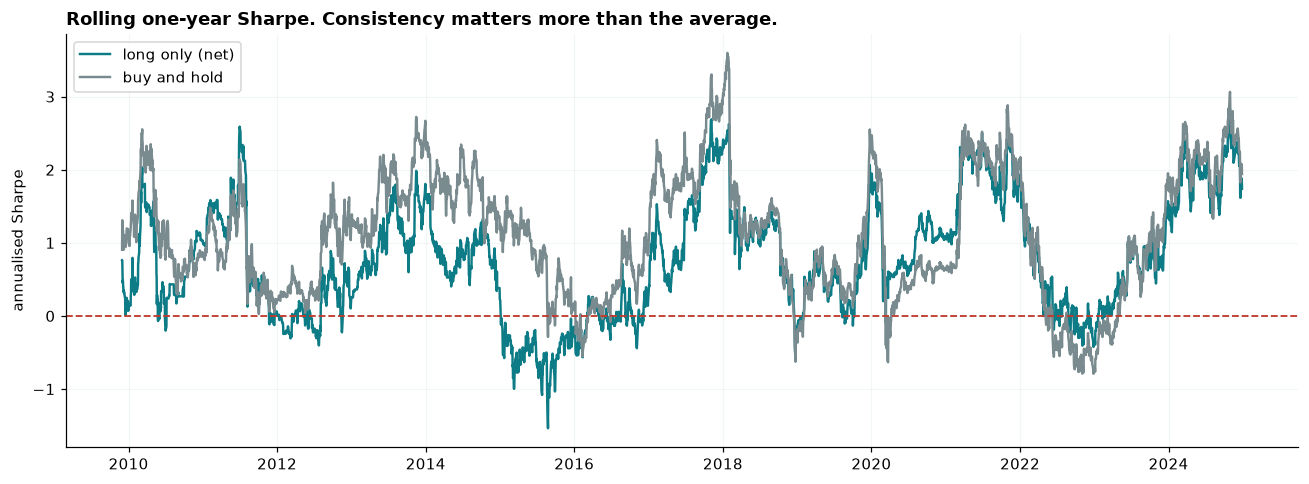

In [14]:
best = max(
    (name for name in books if name != "buy and hold"),
    key=lambda name: performance(books[name]["net"])["sharpe"],
)

book = books[best]
rolling = book["net"].rolling(TRADING_DAYS)
rolling_sharpe = rolling.mean() / rolling.std() * np.sqrt(TRADING_DAYS)

hold_rolling = books["buy and hold"]["net"].rolling(TRADING_DAYS)
hold_sharpe_series = hold_rolling.mean() / hold_rolling.std() * np.sqrt(TRADING_DAYS)

figure, axis = plt.subplots(figsize=(12, 4.5))
axis.plot(rolling_sharpe, color=TEAL, lw=1.6, label=f"{best} (net)")
axis.plot(hold_sharpe_series, color=GREY, lw=1.6, label="buy and hold")
axis.axhline(0, color=RED, ls="--", lw=1.2)

axis.set_title("Rolling one-year Sharpe. Consistency matters more than the average.",
               loc="left", fontweight="bold")
axis.set_ylabel("annualised Sharpe")
axis.legend()

save("04_rolling_sharpe")
plt.show()

### The verdict

Everything in one table, with the comparison that decides it.

In [15]:
verdict = pd.DataFrame({
    name: {
        "sharpe_net": performance(book["net"])["sharpe"],
        "cagr_net": performance(book["net"])["cagr"],
        "max_drawdown": performance(book["net"])["max_drawdown"],
        "cost_drag": book["cost"].sum(),
        "mc_share_positive": distributions[name]["sharpe"].gt(0).mean(),
        "mc_share_beating_hold": distributions[name]["sharpe"].gt(
            performance(books["buy and hold"]["net"])["sharpe"]
        ).mean(),
    }
    for name, book in books.items()
}).T

verdict.round(4)

,sharpe_net,cagr_net,max_drawdown,cost_drag,mc_share_positive,mc_share_beating_hold
binary long/short,0.2787,0.0347,-0.5141,0.9035,0.849,0.000
scaled by conviction,-0.0977,-0.0209,-0.5236,0.8867,0.315,0.000
long only,0.7027,0.0955,-0.2240,0.4515,1.000,0.221
buy and hold,0.8473,0.1464,-0.3372,0.0005,1.000,0.533


In [16]:
hold_sharpe = performance(books["buy and hold"]["net"])["sharpe"]

print(f"Buy and hold net Sharpe : {hold_sharpe:.4f}")
print(f"Trials counted          : {n_trials}")
print()

for name in books:
    if name == "buy and hold":
        continue

    sharpe = performance(books[name]["net"])["sharpe"]
    beats_hold = sharpe > hold_sharpe
    share = distributions[name]["sharpe"].gt(hold_sharpe).mean()

    print(f"{name}")
    print(f"  net Sharpe                      : {sharpe:+.4f}")
    print(f"  beats buy and hold              : {beats_hold}")
    print(f"  share of resampled paths beating: {share:.1%}")
    print()

Buy and hold net Sharpe : 0.8473
Trials counted          : 42

binary long/short
  net Sharpe                      : +0.2787
  beats buy and hold              : False
  share of resampled paths beating: 0.0%

scaled by conviction
  net Sharpe                      : -0.0977
  beats buy and hold              : False
  share of resampled paths beating: 0.0%

long only
  net Sharpe                      : +0.7027
  beats buy and hold              : False
  share of resampled paths beating: 22.1%

